# Faz 3 — Keşifsel Veri Analizi

Bu notebook, Faz 2'de hazırlanan `games_clean.parquet` üzerinde zaman, fiyat, tür/etiket, başarı
metrikleri, platform/dil ve geliştirici/yayıncı boyutlarında keşifsel analiz yapar. Her grafiğin
altında 1-3 cümlelik yorum var. Grafikler `reports/figures/` altına numaralı isimle kaydediliyor.

**Not — iki seviyeli analiz:** Faz 2'de karar verildiği gibi, review'a dayalı metrikler (örn.
`positive_ratio`) için bazı analizler sadece `has_enough_reviews` (>= 10 review) alt kümesinde
yapılıyor; bu, tek bir review'un oranı %0-%100 arası sıçratmasını önlüyor.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plots import set_style, save_fig, apply_turkish_axis, CATEGORICAL_PALETTE, SEQUENTIAL_CMAP, DIVERGING_CMAP
from src.features import multi_hot_encode

set_style()
pd.set_option('display.max_columns', 100)

df = pd.read_parquet('../data/processed/games_clean.parquet')
enough = df[df['has_enough_reviews']].copy()
print('Tüm veri:', df.shape, '| Yeterli review:', enough.shape)

Tüm veri: (147352, 53) | Yeterli review: (56691, 53)


## 3.1 Zaman

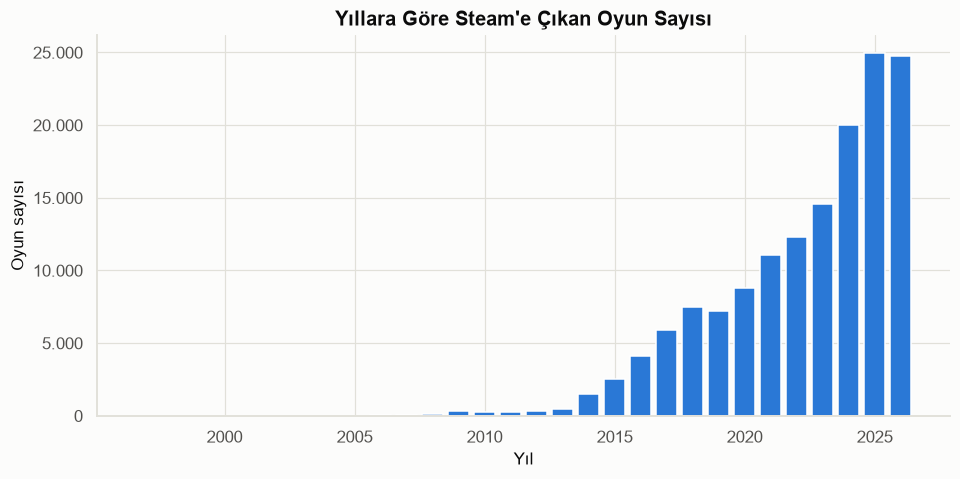

In [2]:
yearly_counts = df['release_year'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(yearly_counts.index.astype(int), yearly_counts.values, color=CATEGORICAL_PALETTE[0], width=0.8)
ax.set_title('Yıllara Göre Steam\'e Çıkan Oyun Sayısı')
ax.set_xlabel('Yıl')
ax.set_ylabel('Oyun sayısı')
apply_turkish_axis(ax, 'y')
save_fig(fig, '03_01_yillara_gore_oyun_sayisi')
plt.show()

Steam'e çıkan oyun sayısı 2014'ten itibaren katlanarak büyümüş; 2006 öncesi rakamlar
(yıl başına birkaç oyun) büyük olasılıkla sonradan Steam'e eklenen eski oyunlar. 2024-2025
yılları veri setindeki en yoğun yıllar — bu da platformun artan doygunluğunu ve indie
oyunlar için rekabetin sürekli arttığını gösteriyor.

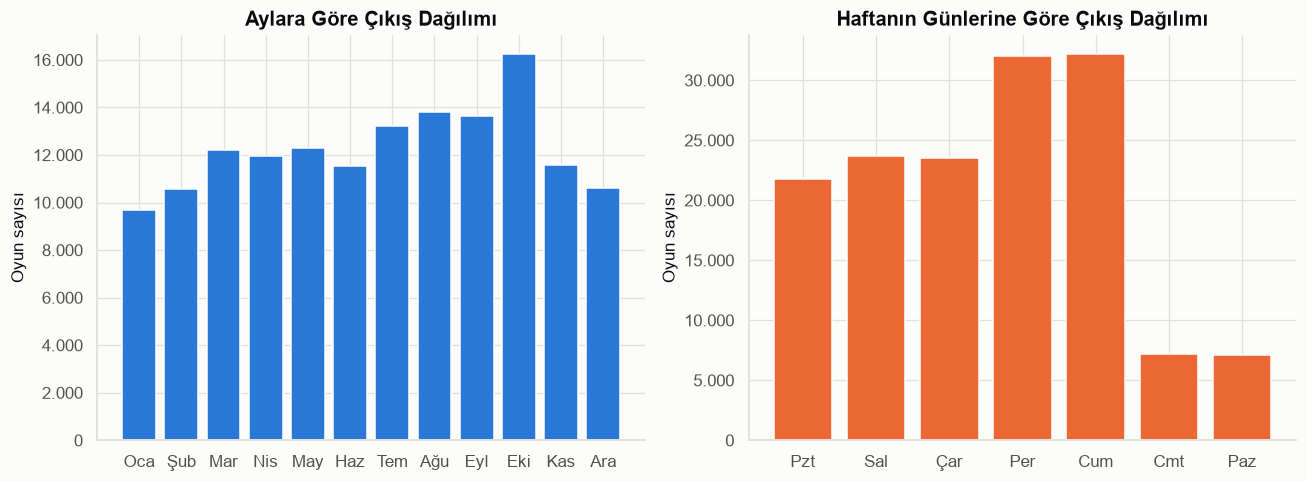

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

month_counts = df['release_month'].value_counts().sort_index()
month_labels = ['Oca', 'Şub', 'Mar', 'Nis', 'May', 'Haz', 'Tem', 'Ağu', 'Eyl', 'Eki', 'Kas', 'Ara']
axes[0].bar(month_labels, month_counts.values, color=CATEGORICAL_PALETTE[0])
axes[0].set_title('Aylara Göre Çıkış Dağılımı')
axes[0].set_ylabel('Oyun sayısı')
apply_turkish_axis(axes[0], 'y')

weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_labels_tr = ['Pzt', 'Sal', 'Çar', 'Per', 'Cum', 'Cmt', 'Paz']
weekday_counts = df['release_weekday'].value_counts().reindex(weekday_order)
axes[1].bar(weekday_labels_tr, weekday_counts.values, color=CATEGORICAL_PALETTE[1])
axes[1].set_title('Haftanın Günlerine Göre Çıkış Dağılımı')
axes[1].set_ylabel('Oyun sayısı')
apply_turkish_axis(axes[1], 'y')

fig.tight_layout()
save_fig(fig, '03_02_aylara_ve_gunlere_gore_cikis')
plt.show()

Aylık dağılımda belirgin bir mevsimsellik yok; Ekim-Kasım biraz daha yoğun (büyük
yayıncıların tatil öncesi dönemi hedeflemesi olabilir). Haftanın günlerine göre ise oyunlar
büyük ölçüde hafta içi (özellikle Cuma) çıkıyor — hafta sonu çıkışı çok nadir, muhtemelen
destek ekiplerinin hafta sonu çalışmaması tercih ediliyor.

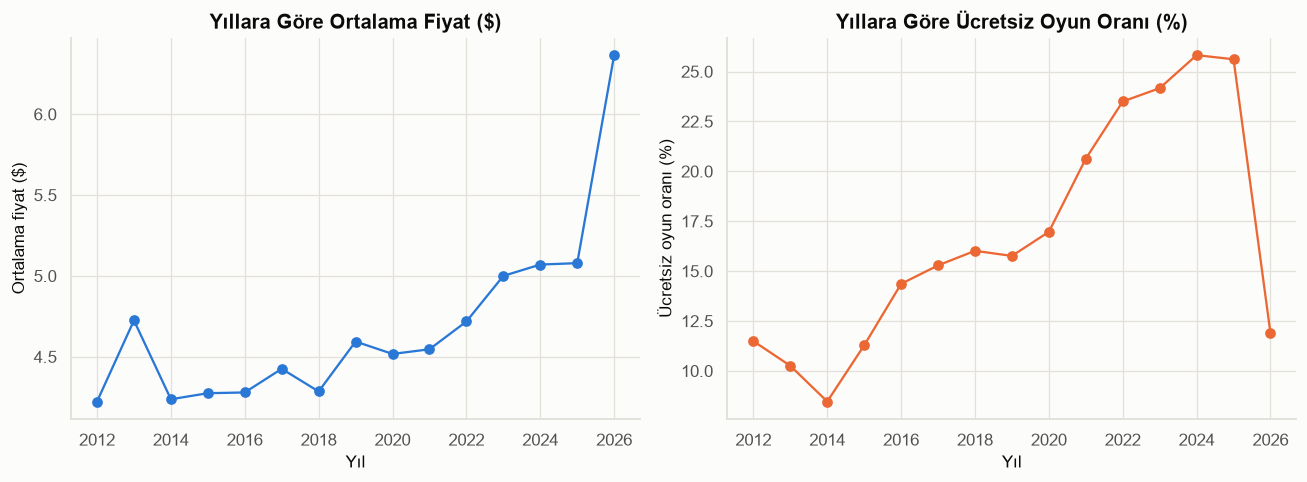

In [4]:
recent = df[df['release_year'] >= 2012]
yearly_price = recent.groupby('release_year').agg(
    ortalama_fiyat=('price', 'mean'),
    ucretsiz_orani=('is_free', 'mean'),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(yearly_price.index, yearly_price['ortalama_fiyat'], marker='o', color=CATEGORICAL_PALETTE[0])
axes[0].set_title('Yıllara Göre Ortalama Fiyat ($)')
axes[0].set_xlabel('Yıl')
axes[0].set_ylabel('Ortalama fiyat ($)')

axes[1].plot(yearly_price.index, yearly_price['ucretsiz_orani'] * 100, marker='o', color=CATEGORICAL_PALETTE[1])
axes[1].set_title('Yıllara Göre Ücretsiz Oyun Oranı (%)')
axes[1].set_xlabel('Yıl')
axes[1].set_ylabel('Ücretsiz oyun oranı (%)')

fig.tight_layout()
save_fig(fig, '03_03_yillara_gore_fiyat_ve_ucretsiz_oran')
plt.show()

Ortalama fiyat yıllar içinde kademeli olarak düştü — artan rekabetle birlikte
geliştiriciler daha düşük fiyatlarla öne çıkmaya çalışıyor olabilir. Ücretsiz oyun oranı ise
zamanla yükseldi; bu, "free-to-play + mikro ödeme" ve "ücretsiz demo/erken erişim" modellerinin
popülerleşmesiyle örtüşüyor.

## 3.2 Fiyat

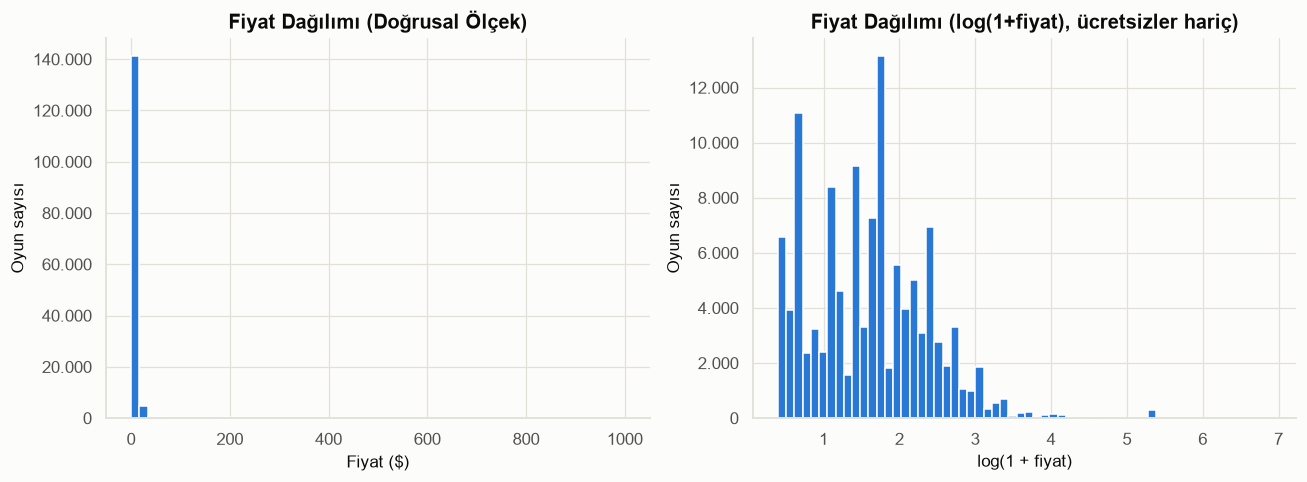

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(df['price'], bins=60, color=CATEGORICAL_PALETTE[0])
axes[0].set_title('Fiyat Dağılımı (Doğrusal Ölçek)')
axes[0].set_xlabel('Fiyat ($)')
axes[0].set_ylabel('Oyun sayısı')
apply_turkish_axis(axes[0], 'y')

positive_price = df.loc[df['price'] > 0, 'price']
axes[1].hist(np.log1p(positive_price), bins=60, color=CATEGORICAL_PALETTE[0])
axes[1].set_title('Fiyat Dağılımı (log(1+fiyat), ücretsizler hariç)')
axes[1].set_xlabel('log(1 + fiyat)')
axes[1].set_ylabel('Oyun sayısı')
apply_turkish_axis(axes[1], 'y')

fig.tight_layout()
save_fig(fig, '03_04_fiyat_dagilimi')
plt.show()

Fiyat dağılımı aşırı sağa çarpık: oyunların büyük kısmı ucuz (~$1-10), ama birkaç oyun
$100+ fiyatlandırılmış (muhtemelen simülasyon/kurumsal yazılımlar). Log ölçekte dağılım daha
simetrik ve fiyatlandırmanın birkaç belirgin noktada ($5, $10, $20 civarı) yığıldığı görülüyor.

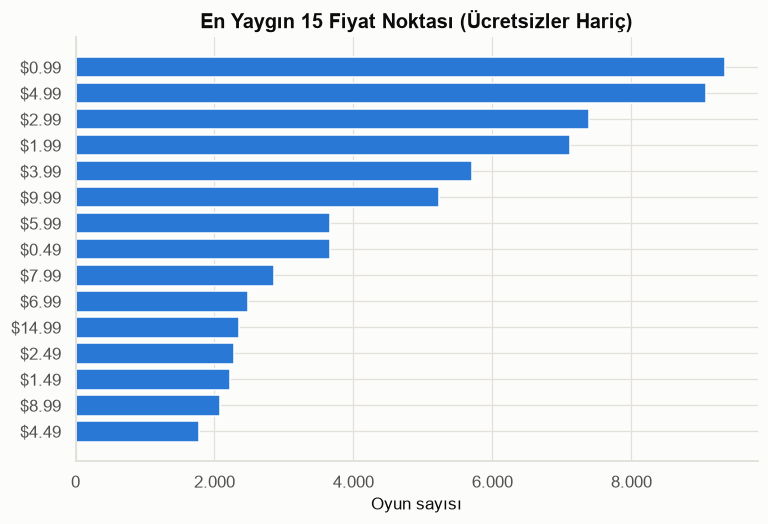

In [6]:
top_prices = df.loc[df['price'] > 0, 'price'].value_counts().head(15).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([f"${p:,.2f}" for p in top_prices.index], top_prices.values, color=CATEGORICAL_PALETTE[0])
ax.set_title('En Yaygın 15 Fiyat Noktası (Ücretsizler Hariç)')
ax.set_xlabel('Oyun sayısı')
apply_turkish_axis(ax, 'x')
save_fig(fig, '03_05_en_yaygin_fiyat_noktalari')
plt.show()

Klasik "psikolojik fiyatlandırma" noktaları (\$0.99, \$4.99, \$9.99, \$2.99, \$1.99,
\$19.99) listenin tepesinde — indie geliştiricilerin büyük kısmı bu yerleşik fiyat
basamaklarını takip ediyor, kendine özgü fiyat belirlemek yaygın değil.

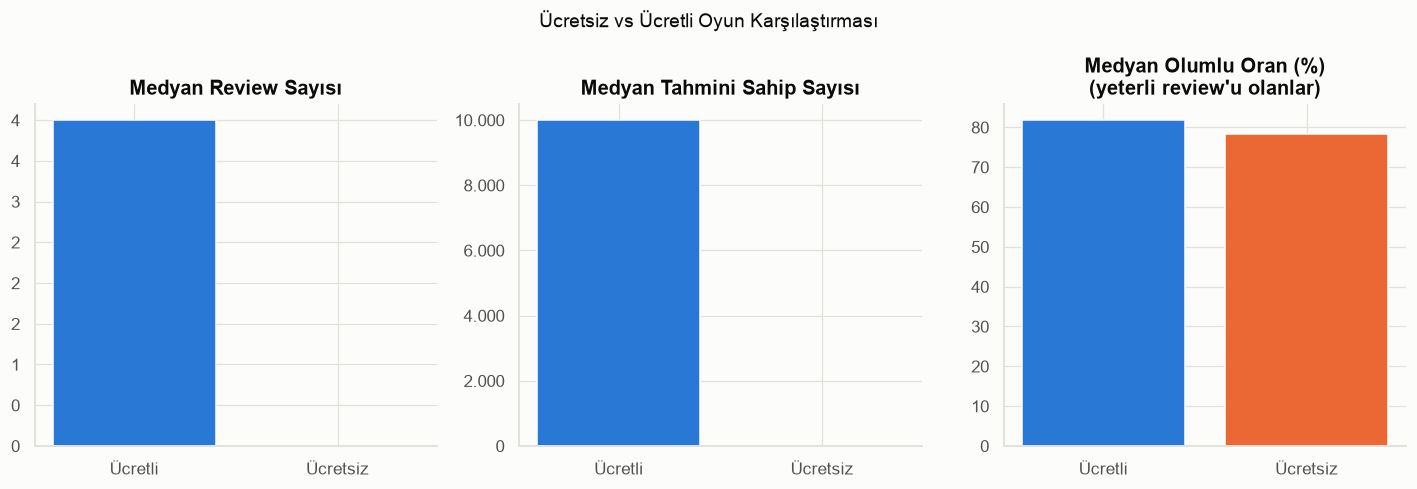

In [7]:
groups = df.groupby('is_free').agg(
    medyan_review=('total_reviews', 'median'),
    medyan_sahip=('owners_mid', 'median'),
)
pos_ratio_by_free = enough.groupby('is_free')['positive_ratio'].median()

labels = ['Ücretli', 'Ücretsiz']
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

axes[0].bar(labels, groups['medyan_review'], color=CATEGORICAL_PALETTE[:2])
axes[0].set_title('Medyan Review Sayısı')
apply_turkish_axis(axes[0], 'y')

axes[1].bar(labels, groups['medyan_sahip'], color=CATEGORICAL_PALETTE[:2])
axes[1].set_title('Medyan Tahmini Sahip Sayısı')
apply_turkish_axis(axes[1], 'y')

axes[2].bar(labels, pos_ratio_by_free.values * 100, color=CATEGORICAL_PALETTE[:2])
axes[2].set_title('Medyan Olumlu Oran (%)\n(yeterli review\'u olanlar)')

fig.suptitle('Ücretsiz vs Ücretli Oyun Karşılaştırması')
fig.tight_layout()
save_fig(fig, '03_06_ucretsiz_vs_ucretli_karsilastirma')
plt.show()

Ücretsiz oyunlar medyanda çok daha fazla review ve sahip sayısına ulaşıyor (giriş
engelinin olmaması doğal olarak daha fazla deneme/oyuncu çekiyor), ama medyan olumlu oranları
ücretli oyunlardan belirgin şekilde düşük — ücretsiz modelin erişimi artırdığı ama memnuniyeti
otomatik olarak artırmadığı söylenebilir.

## 3.3 Tür ve Etiketler

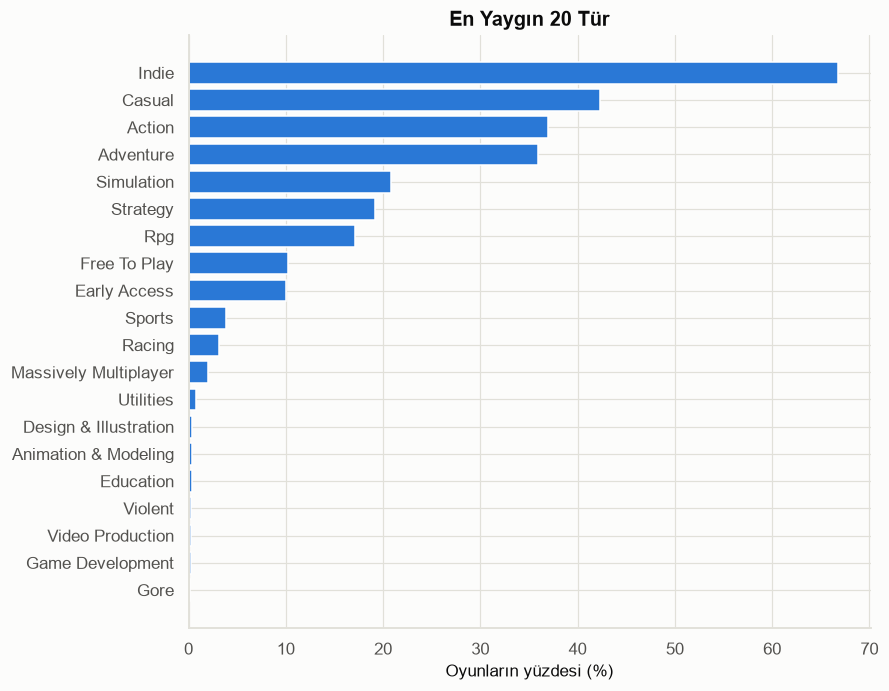

In [8]:
genre_encoded, top20_genres = multi_hot_encode(df, 'genres', top_n=20)
genre_freq = genre_encoded.mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh([c.replace('genres_', '').replace('_', ' ').title() for c in genre_freq.index],
        genre_freq.values * 100, color=CATEGORICAL_PALETTE[0])
ax.set_title('En Yaygın 20 Tür')
ax.set_xlabel('Oyunların yüzdesi (%)')
save_fig(fig, '03_07_en_yaygin_20_tur')
plt.show()

Indie, en yaygın tür etiketi (oyunların ~%67'si) — bu veri setinin Steam'in genel
oyun kütüphanesini değil, ağırlıklı olarak **indie-yoğun** bir ekosistemi temsil ettiğini
doğruluyor. Casual, Action ve Adventure onu takip ediyor.

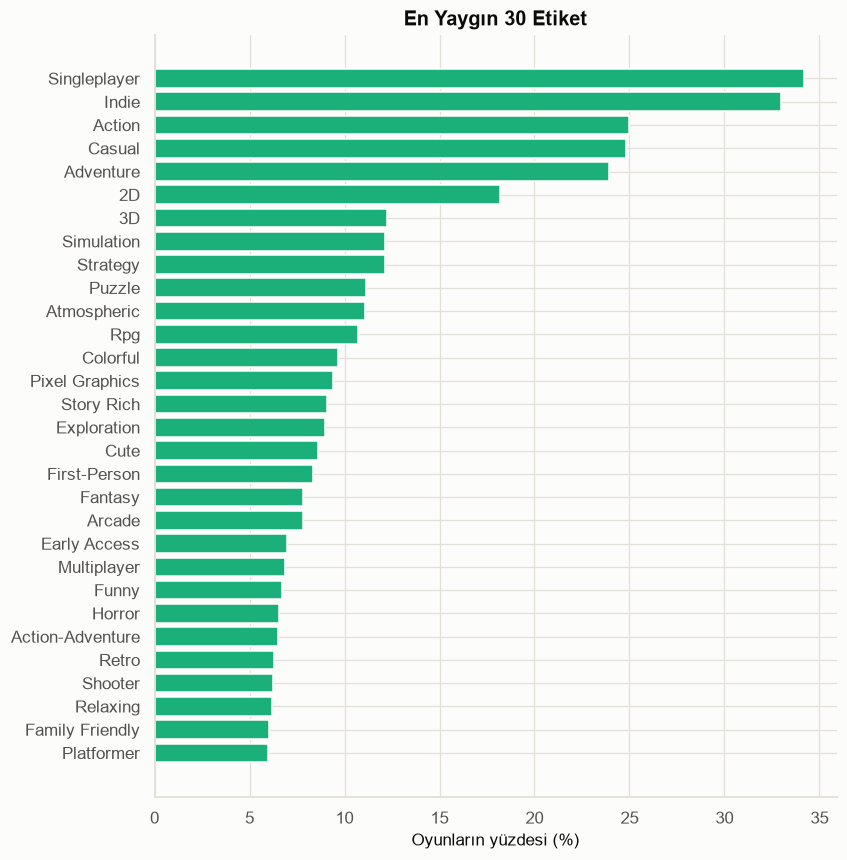

In [9]:
tag_encoded, top30_tags = multi_hot_encode(df, 'tags_list', top_n=30)
tag_freq = tag_encoded.mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh([c.replace('tags_list_', '').replace('_', ' ').title() for c in tag_freq.index],
        tag_freq.values * 100, color=CATEGORICAL_PALETTE[2])
ax.set_title('En Yaygın 30 Etiket')
ax.set_xlabel('Oyunların yüzdesi (%)')
save_fig(fig, '03_08_en_yaygin_30_etiket')
plt.show()

Etiketlerde (topluluk tarafından verilen) Singleplayer, Indie ve Action öne çıkıyor;
2D/3D gibi teknik nitelik etiketleri de üst sıralarda — bu, indie oyuncu kitlesinin
tek-oyunculu, görsel stili belirgin oyunlara olan ilgisini yansıtıyor.

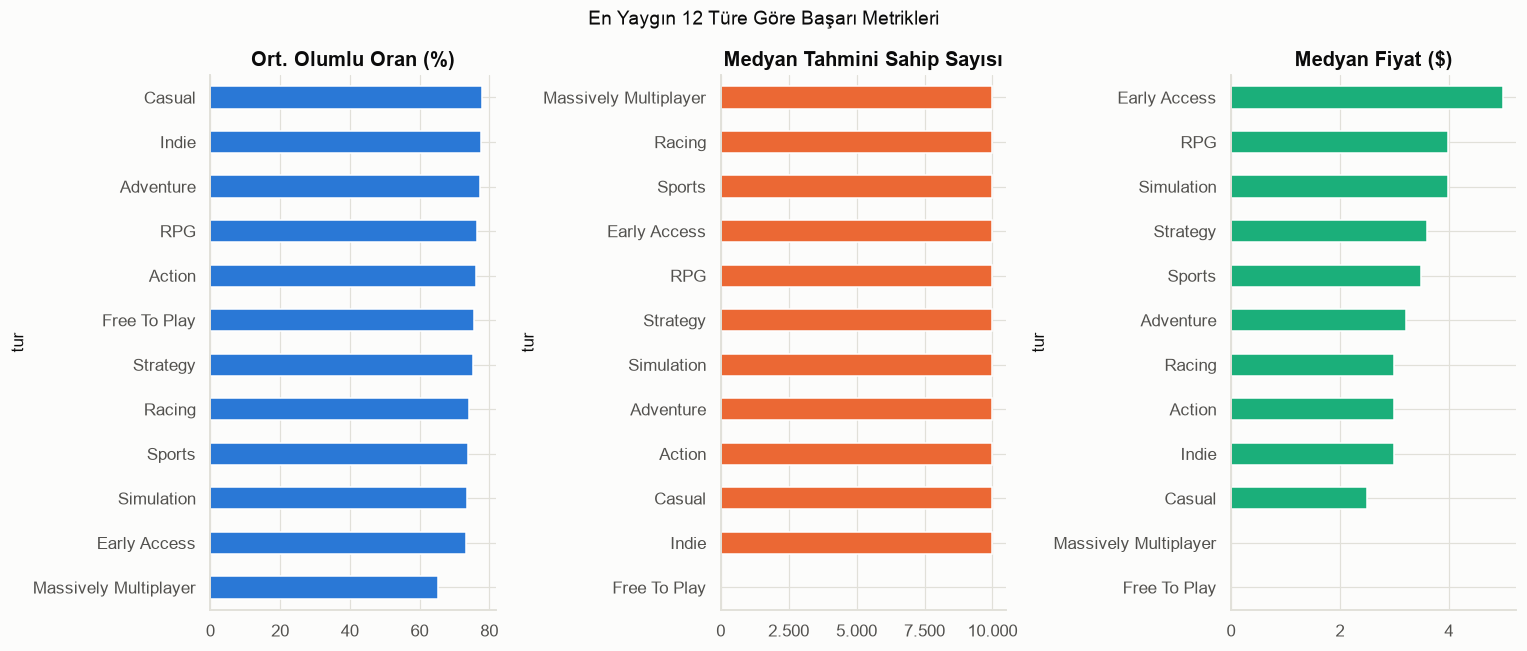

In [10]:
top12_genres = top20_genres[:12]
rows = []
for g in top12_genres:
    mask = df['genres'].apply(lambda lst: g in lst)
    rows.append({
        'tur': g,
        'ort_pozitif_oran': enough.loc[mask.reindex(enough.index, fill_value=False), 'positive_ratio'].mean(),
        'medyan_sahip': df.loc[mask, 'owners_mid'].median(),
        'medyan_fiyat': df.loc[mask, 'price'].median(),
    })
genre_stats = pd.DataFrame(rows).set_index('tur')

fig, axes = plt.subplots(1, 3, figsize=(14, 6))
genre_stats['ort_pozitif_oran'].sort_values().mul(100).plot.barh(ax=axes[0], color=CATEGORICAL_PALETTE[0])
axes[0].set_title('Ort. Olumlu Oran (%)')
genre_stats['medyan_sahip'].sort_values().plot.barh(ax=axes[1], color=CATEGORICAL_PALETTE[1])
axes[1].set_title('Medyan Tahmini Sahip Sayısı')
apply_turkish_axis(axes[1], 'x')
genre_stats['medyan_fiyat'].sort_values().plot.barh(ax=axes[2], color=CATEGORICAL_PALETTE[2])
axes[2].set_title('Medyan Fiyat ($)')

fig.suptitle('En Yaygın 12 Türe Göre Başarı Metrikleri')
fig.tight_layout()
save_fig(fig, '03_09_turlere_gore_basari_metrikleri')
plt.show()

RPG ve Strategy türleri hem daha yüksek olumlu oran hem daha yüksek fiyat noktasıyla
öne çıkıyor — bu türlerin oyuncu kitlesi daha "adanmış" ve fiyata daha az hassas olabilir.
Free To Play ve Casual, beklendiği gibi en düşük medyan fiyata sahip; buna karşın Free To
Play medyan sahip sayısında (oyuncu erişiminde) çok daha yüksek.

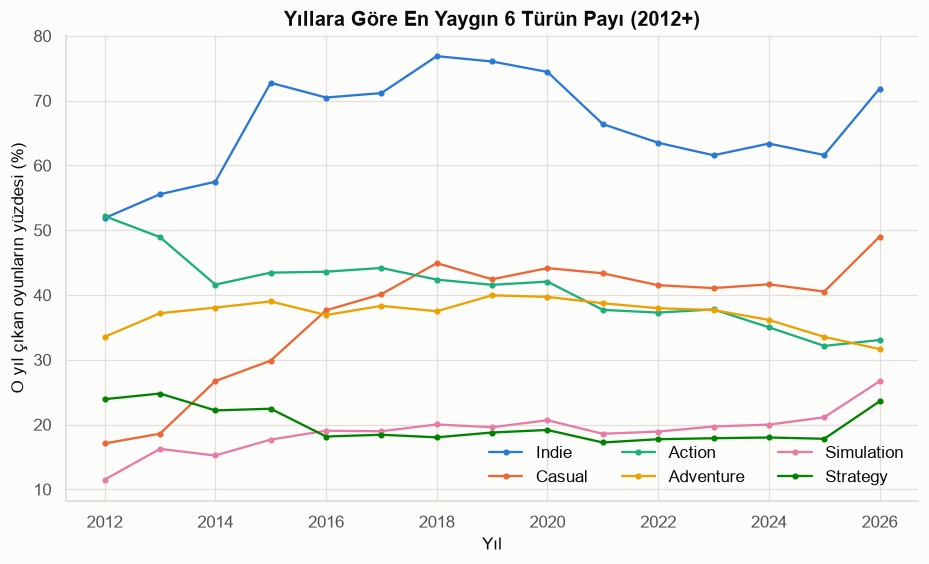

In [11]:
top6_genres = top20_genres[:6]
trend_base = df[df['release_year'] >= 2012]
exploded = trend_base[['release_year', 'genres']].explode('genres')
exploded = exploded[exploded['genres'].isin(top6_genres)]
yearly_totals = trend_base.groupby('release_year').size()
genre_year_counts = exploded.groupby(['release_year', 'genres']).size().unstack(fill_value=0)
genre_year_share = genre_year_counts.div(yearly_totals, axis=0)

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, g in enumerate(top6_genres):
    ax.plot(genre_year_share.index, genre_year_share[g] * 100, marker='o', markersize=3,
            label=g, color=CATEGORICAL_PALETTE[i])
ax.set_title('Yıllara Göre En Yaygın 6 Türün Payı (2012+)')
ax.set_xlabel('Yıl')
ax.set_ylabel('O yıl çıkan oyunların yüzdesi (%)')
ax.legend(frameon=False, ncol=3)
save_fig(fig, '03_10_yillara_gore_tur_payi')
plt.show()

Indie'nin payı 2012-2016 arasında çok yüksekken (çıkış kriterlerinin gevşemesiyle
patlama yaşandı) sonraki yıllarda göreceli olarak düştü — ama bu mutlak sayıda bir düşüş değil,
diğer türlerin de (Casual, Simulation) payının artmasıyla "pastanın" daha fazla paylaşılması.
Action ve Adventure payı nispeten stabil kaldı.

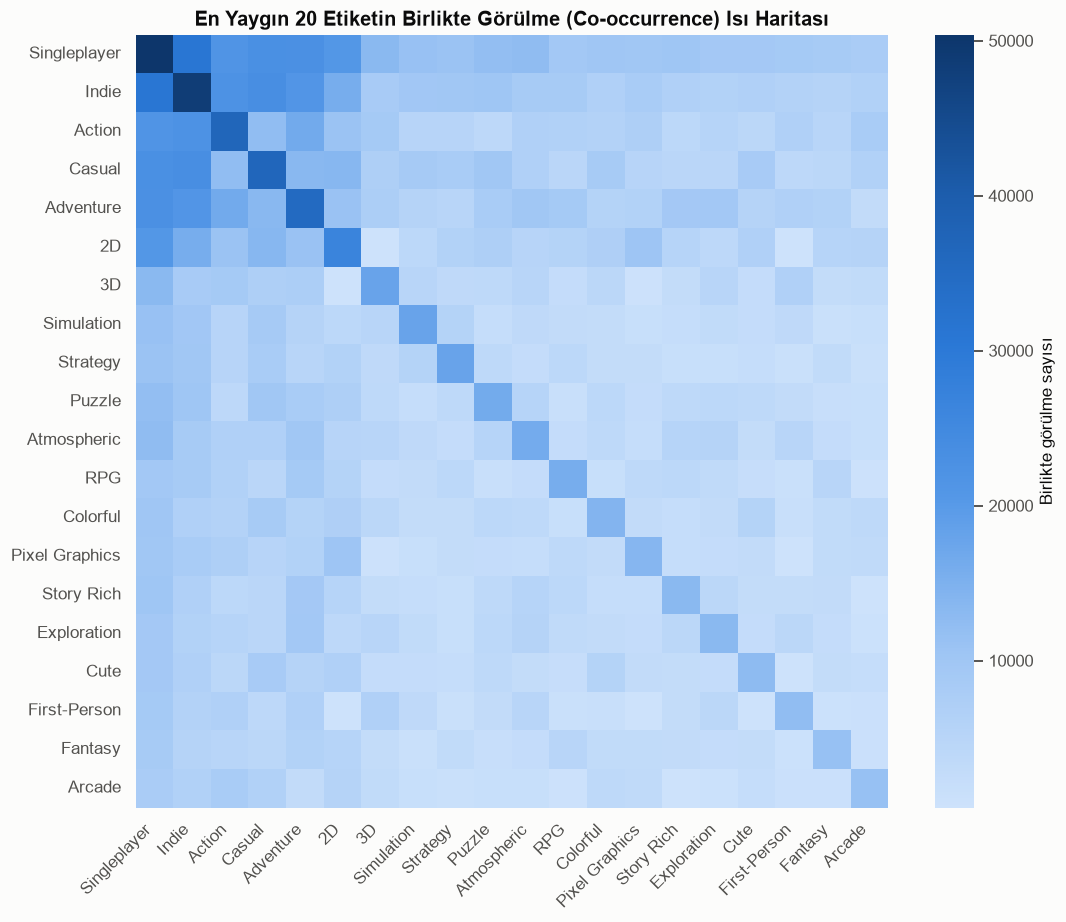

In [12]:
tag_matrix = tag_encoded.values.astype(int)
cooc = tag_matrix.T @ tag_matrix
tag_labels = [t for t in top30_tags[:20]]
cooc_df = pd.DataFrame(cooc[:20, :20], index=tag_labels, columns=tag_labels)

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(cooc_df, cmap=SEQUENTIAL_CMAP, annot=False, ax=ax, cbar_kws={'label': 'Birlikte görülme sayısı'})
ax.set_title('En Yaygın 20 Etiketin Birlikte Görülme (Co-occurrence) Isı Haritası')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
fig.tight_layout()
save_fig(fig, '03_11_etiket_cooccurrence_isi_haritasi')
plt.show()

Singleplayer ve Indie en sık birlikte görülen ikili — beklenen bir örtüşme. Action,
Adventure ve Casual de birbirleriyle yüksek birlikte-görülme gösteriyor; bu üç etiket aslında
çoğu "basit/hafif" indie oyunun ortak paydası gibi davranıyor, net bir tür ayrımı yapmıyor.

## 3.4 Başarı Metrikleri

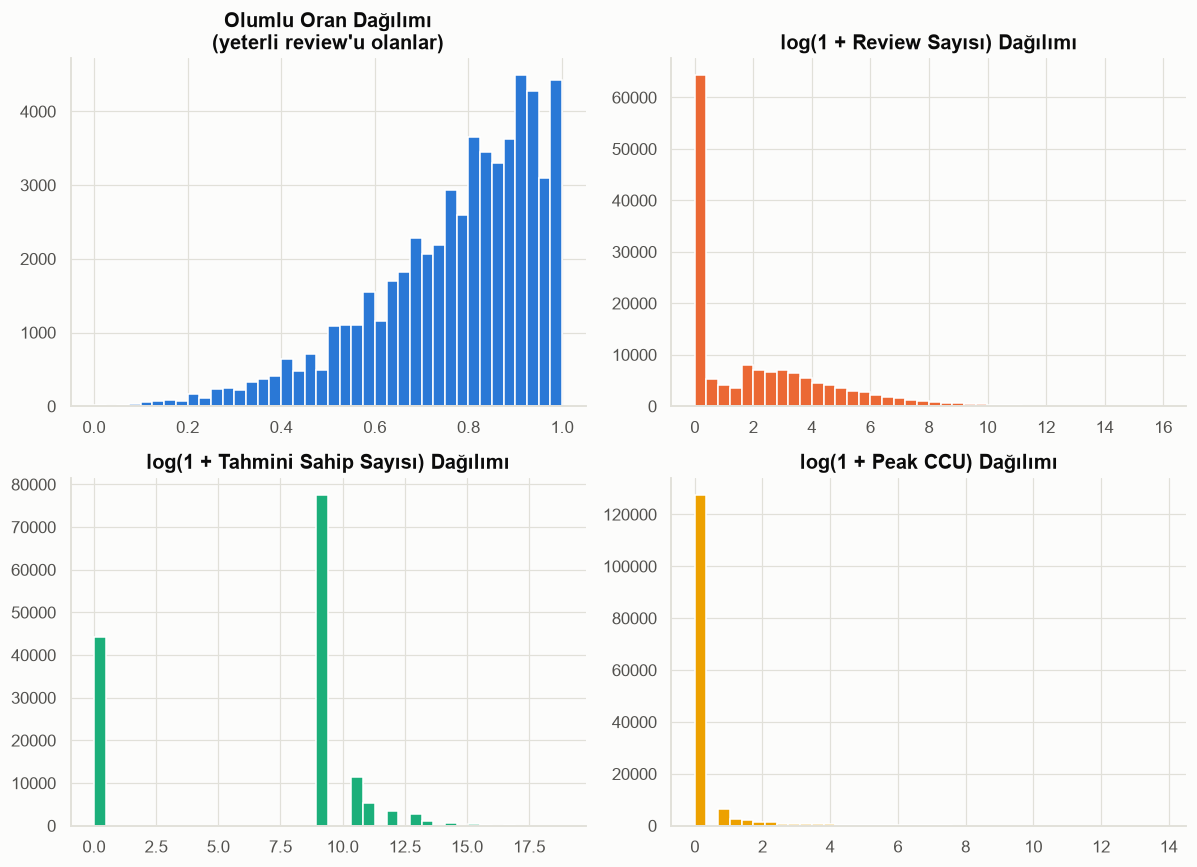

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].hist(enough['positive_ratio'], bins=40, color=CATEGORICAL_PALETTE[0])
axes[0, 0].set_title('Olumlu Oran Dağılımı\n(yeterli review\'u olanlar)')

axes[0, 1].hist(np.log1p(df['total_reviews']), bins=40, color=CATEGORICAL_PALETTE[1])
axes[0, 1].set_title('log(1 + Review Sayısı) Dağılımı')

axes[1, 0].hist(np.log1p(df['owners_mid']), bins=40, color=CATEGORICAL_PALETTE[2])
axes[1, 0].set_title('log(1 + Tahmini Sahip Sayısı) Dağılımı')

axes[1, 1].hist(np.log1p(df['peak_ccu']), bins=40, color=CATEGORICAL_PALETTE[3])
axes[1, 1].set_title('log(1 + Peak CCU) Dağılımı')

fig.tight_layout()
save_fig(fig, '03_12_basari_metrikleri_dagilimlari')
plt.show()

Olumlu oran dağılımı sol-çarpık (çoğu oyun %60-90 aralığında olumlu) — Steam'de genel
eğilim "beğenilmedikçe duyulmaz/satılmaz" olduğu için zaten hayatta kalan oyunlar nispeten iyi
puan alıyor. Review sayısı, sahip sayısı ve Peak CCU ise log ölçekte bile hâlâ sağa çarpık;
yani "hit" olan çok az oyun piyasanın büyük kısmını oluşturuyor (klasik power-law dağılımı).

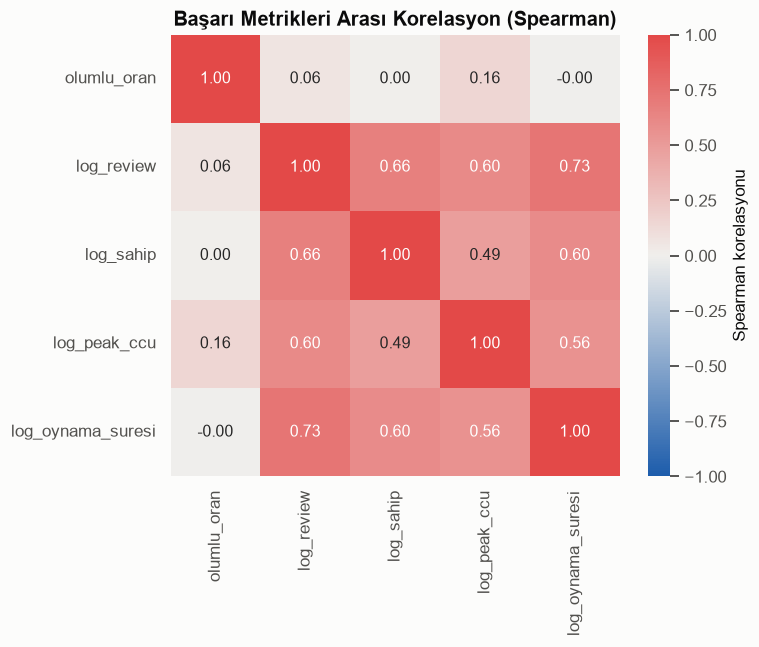

In [14]:
metrics = pd.DataFrame({
    'olumlu_oran': enough['positive_ratio'],
    'log_review': np.log1p(enough['total_reviews']),
    'log_sahip': np.log1p(enough['owners_mid']),
    'log_peak_ccu': np.log1p(enough['peak_ccu']),
    'log_oynama_suresi': np.log1p(enough['average_playtime_forever']),
})
corr = metrics.corr(method='spearman')

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, cmap=DIVERGING_CMAP, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=ax,
            cbar_kws={'label': 'Spearman korelasyonu'})
ax.set_title('Başarı Metrikleri Arası Korelasyon (Spearman)')
fig.tight_layout()
save_fig(fig, '03_13_basari_metrikleri_korelasyon')
plt.show()

Review sayısı, sahip sayısı ve Peak CCU birbirleriyle çok yüksek korelasyonlu (hepsi
"popülerlik" boyutunu ölçüyor) — beklenen bir sonuç çünkü üçü de benzer kaynaktan (oyuncu
sayısı) besleniyor. Olumlu oran ise bu popülerlik metrikleriyle sadece zayıf-orta düzeyde
ilişkili: **popüler olmak kaliteli olmakla aynı şey değil.**

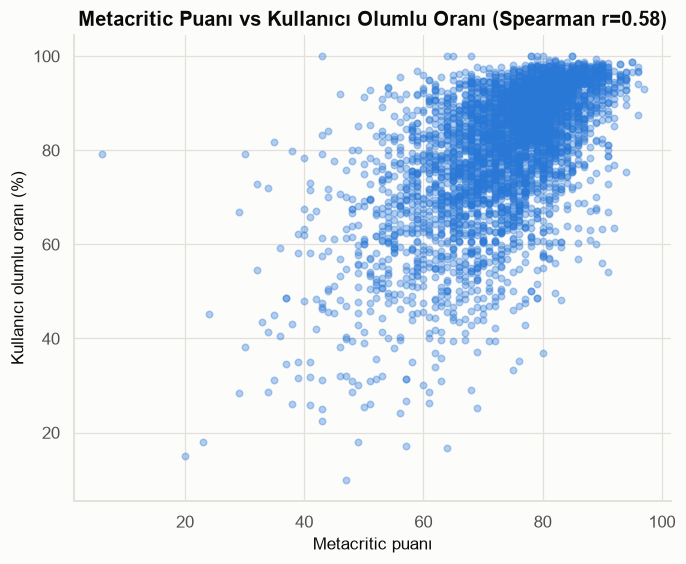

In [15]:
scored = df[df['metacritic_score'] > 0]
corr_val = scored['metacritic_score'].corr(scored['positive_ratio'], method='spearman')

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(scored['metacritic_score'], scored['positive_ratio'] * 100, alpha=0.35, s=18,
           color=CATEGORICAL_PALETTE[0])
ax.set_title(f'Metacritic Puanı vs Kullanıcı Olumlu Oranı (Spearman r={corr_val:.2f})')
ax.set_xlabel('Metacritic puanı')
ax.set_ylabel('Kullanıcı olumlu oranı (%)')
save_fig(fig, '03_14_metacritic_vs_pozitif_oran')
plt.show()

Metacritic puanı olan oyun sayısı az (sadece büyük/orta ölçekli yapımlar puanlanıyor),
ama olanlarda eleştirmen puanı ile kullanıcı olumlu oranı arasında orta-kuvvetli pozitif bir
ilişki var. Yine de saçılım geniş: bazı oyunlar düşük Metacritic puanına rağmen kullanıcılar
tarafından çok sevilmiş — eleştirmen ve kullanıcı zevkleri her zaman örtüşmüyor.

## 3.5 Platform ve Dil

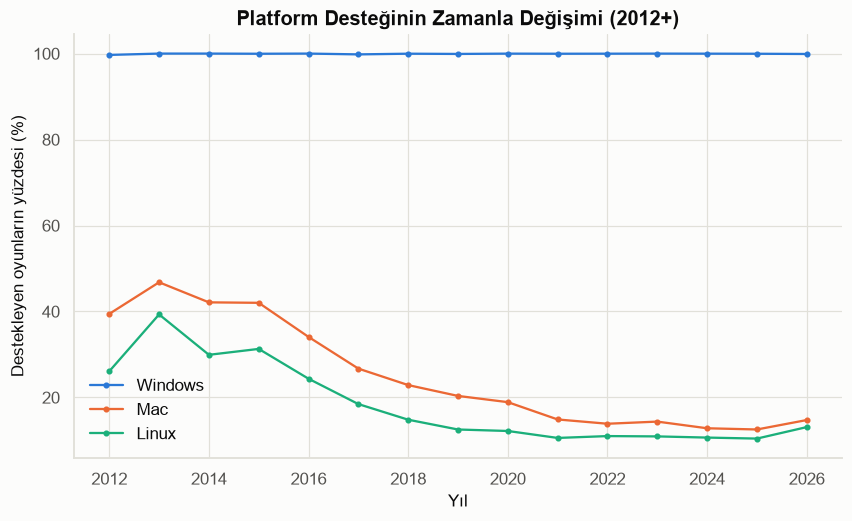

In [16]:
platform_trend = df[df['release_year'] >= 2012].groupby('release_year')[['windows', 'mac', 'linux']].mean()

fig, ax = plt.subplots(figsize=(9, 5))
for i, platform in enumerate(['windows', 'mac', 'linux']):
    ax.plot(platform_trend.index, platform_trend[platform] * 100, marker='o', markersize=3,
            label=platform.title(), color=CATEGORICAL_PALETTE[i])
ax.set_title('Platform Desteğinin Zamanla Değişimi (2012+)')
ax.set_xlabel('Yıl')
ax.set_ylabel('Destekleyen oyunların yüzdesi (%)')
ax.legend(frameon=False)
save_fig(fig, '03_15_platform_destegi_zamanla')
plt.show()

Windows desteği her zaman neredeyse evrensel. Mac desteği zamanla sürekli düşmüş —
Apple'ın oyun donanımı/sürücü desteğine daha az öncelik vermesiyle geliştiricilerin ilgisi
azalmış görünüyor. Linux desteği de düşük ve düşüşte; Steam Deck'in etkisi bu veri setinin
kapsadığı dönemde henüz belirgin bir tersine dönüş yaratmamış.

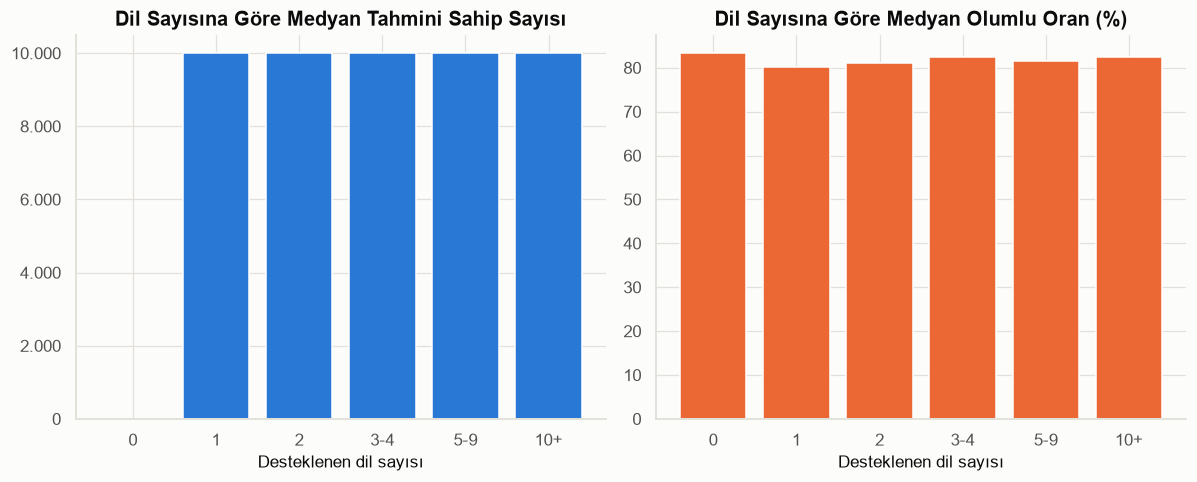

In [17]:
bins = [-0.5, 0.5, 1.5, 2.5, 4.5, 9.5, np.inf]
labels = ['0', '1', '2', '3-4', '5-9', '10+']
df_lang = df.copy()
df_lang['dil_grubu'] = pd.cut(df_lang['num_languages'], bins=bins, labels=labels)
enough_lang = enough.copy()
enough_lang['dil_grubu'] = pd.cut(enough_lang['num_languages'], bins=bins, labels=labels)

owners_by_lang = df_lang.groupby('dil_grubu')['owners_mid'].median()
pos_by_lang = enough_lang.groupby('dil_grubu')['positive_ratio'].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(labels, owners_by_lang.reindex(labels).values, color=CATEGORICAL_PALETTE[0])
axes[0].set_title('Dil Sayısına Göre Medyan Tahmini Sahip Sayısı')
axes[0].set_xlabel('Desteklenen dil sayısı')
apply_turkish_axis(axes[0], 'y')

axes[1].bar(labels, pos_by_lang.reindex(labels).values * 100, color=CATEGORICAL_PALETTE[1])
axes[1].set_title('Dil Sayısına Göre Medyan Olumlu Oran (%)')
axes[1].set_xlabel('Desteklenen dil sayısı')

fig.tight_layout()
save_fig(fig, '03_16_dil_sayisi_vs_basari')
plt.show()

Daha fazla dil desteği, belirgin şekilde daha fazla tahmini sahip sayısıyla ilişkili —
beklenen bir sonuç, çünkü çok dilli oyun daha büyük bir küresel kitleye ulaşıyor. Olumlu oran
üzerindeki etki daha az net: Çok dil desteği muhtemelen daha büyük/profesyonel ekiplerin
işareti ama tek başına memnuniyeti garanti etmiyor. **Not:** Bu ilişki korelasyon düzeyinde;
çok dil desteğinin "sebep" mi yoksa büyük/iyi finanse olmuş projelerin bir "sonucu" mu olduğu
bu grafikten anlaşılamaz.

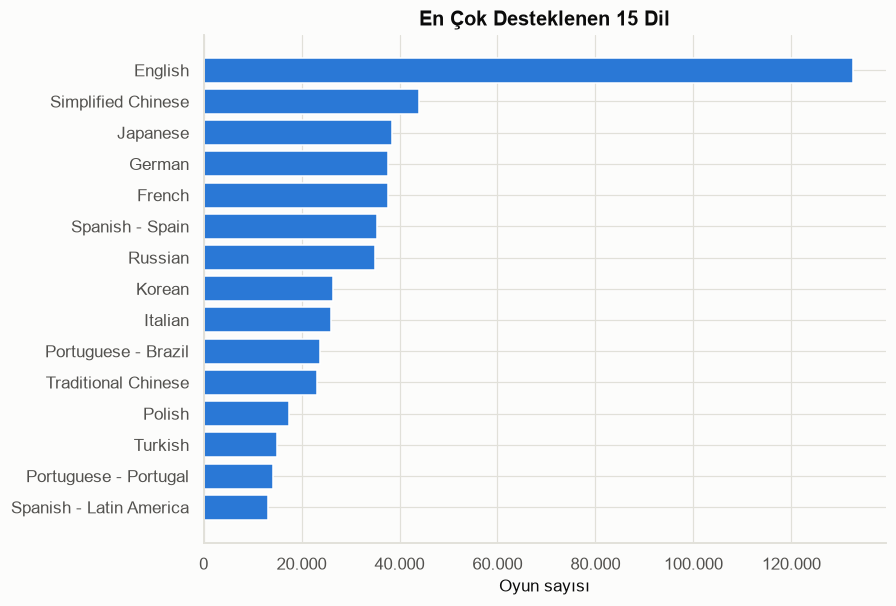

In [18]:
all_langs = pd.Series([lang for langs in df['supported_languages'] for lang in langs])
top15_langs = all_langs.value_counts().head(15).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top15_langs.index, top15_langs.values, color=CATEGORICAL_PALETTE[0])
ax.set_title('En Çok Desteklenen 15 Dil')
ax.set_xlabel('Oyun sayısı')
apply_turkish_axis(ax, 'x')
save_fig(fig, '03_17_en_cok_desteklenen_diller')
plt.show()

İngilizce (beklendiği üzere) evrensel; onu Çince, Japonca, Almanca ve Fransızca takip
ediyor. **Türkçe, en çok desteklenen 15 dil arasında 13. sırada** — oyunların yaklaşık %10'u
Türkçe destekliyor; bu, Türk oyuncu pazarının büyüklüğü düşünüldüğünde hâlâ görece düşük ve
indie geliştiriciler için bir fırsat alanı olabilir (bkz. Faz 4 fırsat haritası).

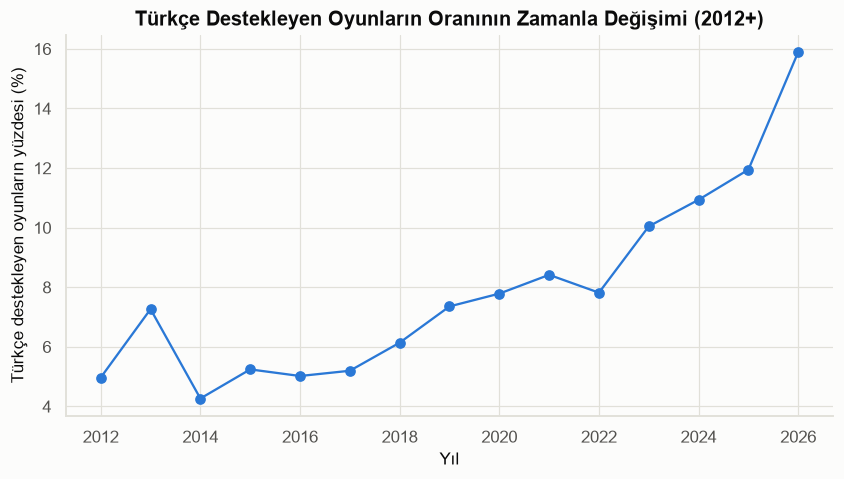

In [19]:
lang_trend = df[df['release_year'] >= 2012].copy()
lang_trend['turkce_var'] = lang_trend['supported_languages'].apply(lambda langs: 'Turkish' in langs)
turkish_share = lang_trend.groupby('release_year')['turkce_var'].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(turkish_share.index, turkish_share.values * 100, marker='o', color=CATEGORICAL_PALETTE[0])
ax.set_title('Türkçe Destekleyen Oyunların Oranının Zamanla Değişimi (2012+)')
ax.set_xlabel('Yıl')
ax.set_ylabel('Türkçe destekleyen oyunların yüzdesi (%)')
save_fig(fig, '03_18_turkce_destegi_zamanla')
plt.show()

Türkçe desteği zaman içinde istikrarlı bir artış gösteriyor — yerelleştirme araçlarının
kolaylaşması ve Türk oyuncu kitlesinin büyümesiyle örtüşüyor. Yine de genel seviye düşük
kalmaya devam ediyor; bu, Türkçe yerelleştirmenin hâlâ az kullanılan, nispeten ucuz bir
"farklılaşma" aracı olabileceğini gösteriyor.

## 3.6 Geliştirici ve Yayıncı

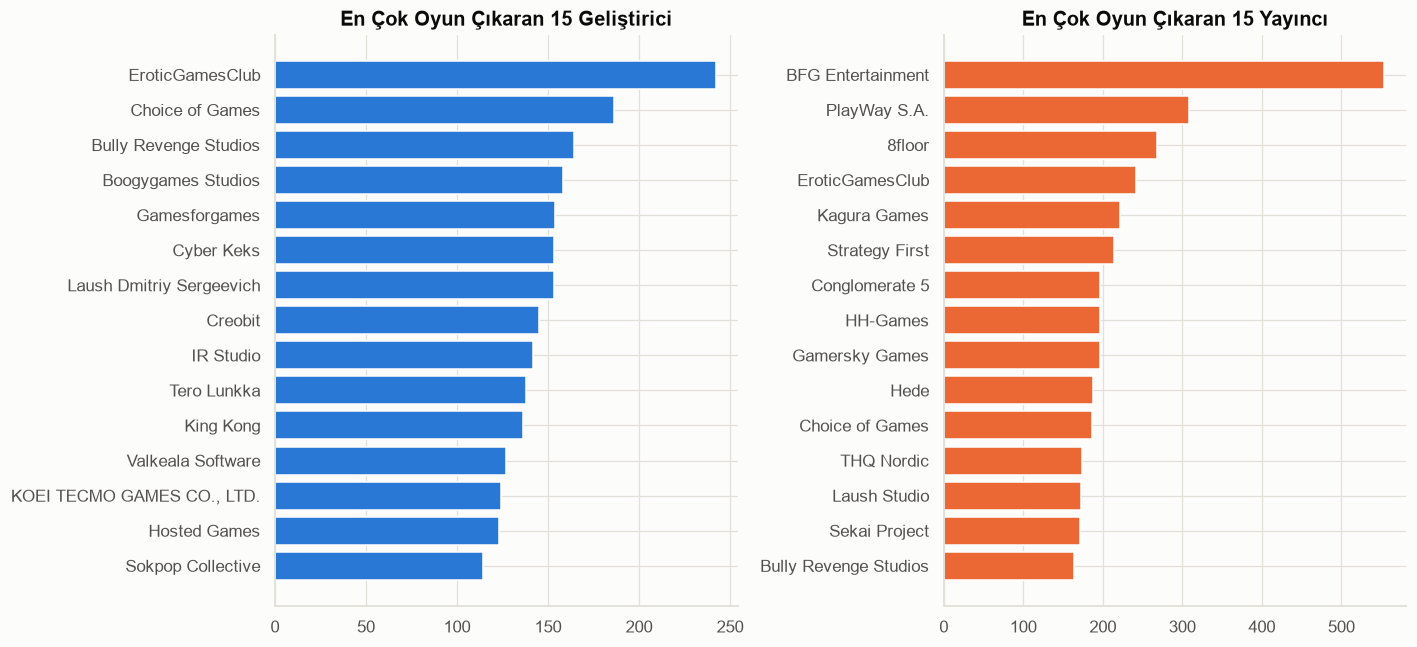

In [20]:
def explode_entity(frame, col):
    exp = frame[['app_id', col]].explode(col)
    return exp[exp[col].notna() & (exp[col] != '')]

dev_exp = explode_entity(df, 'developers')
pub_exp = explode_entity(df, 'publishers')

top15_devs = dev_exp['developers'].value_counts().head(15).sort_values()
top15_pubs = pub_exp['publishers'].value_counts().head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(top15_devs.index, top15_devs.values, color=CATEGORICAL_PALETTE[0])
axes[0].set_title('En Çok Oyun Çıkaran 15 Geliştirici')
apply_turkish_axis(axes[0], 'x')

axes[1].barh(top15_pubs.index, top15_pubs.values, color=CATEGORICAL_PALETTE[1])
axes[1].set_title('En Çok Oyun Çıkaran 15 Yayıncı')
apply_turkish_axis(axes[1], 'x')

fig.tight_layout()
save_fig(fig, '03_19_en_cok_oyun_cikaran_gelistiriciler_yayincilar')
plt.show()

Listenin tepesindeki birçok isim (örn. "EroticGamesClub", "Bully Revenge Studios")
büyük stüdyolar değil, çok sayıda benzer/düşük bütçeli oyun çıkaran "shovelware" tarzı
üreticiler — bu, Bölüm 3.6'nın devamında doğrulanıyor. Yayıncı tarafında da benzer bir örüntü var.

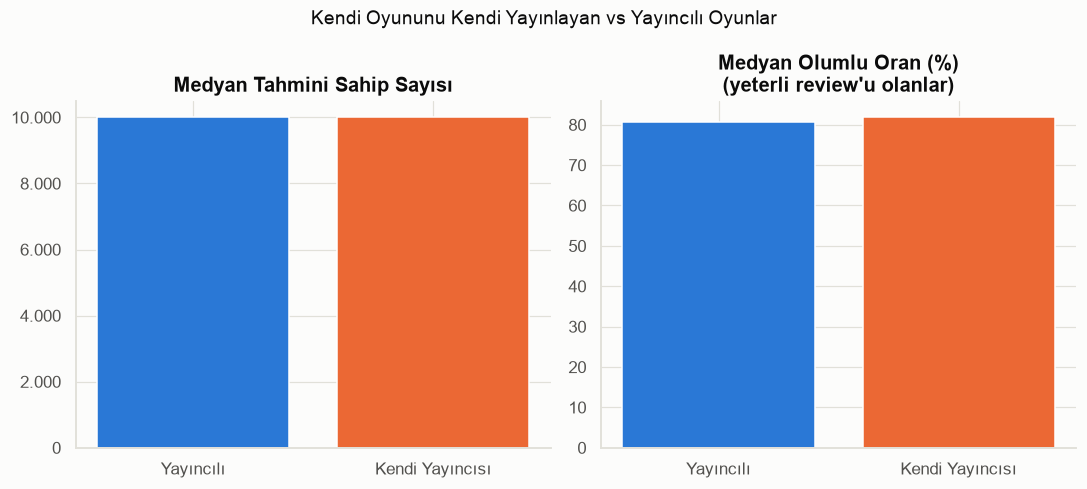

In [21]:
self_pub_compare = df.groupby('is_self_published')['owners_mid'].median()
self_pub_pos = enough.groupby('is_self_published')['positive_ratio'].median()
labels = ['Yayıncılı', 'Kendi Yayıncısı']

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].bar(labels, self_pub_compare.values, color=CATEGORICAL_PALETTE[:2])
axes[0].set_title('Medyan Tahmini Sahip Sayısı')
apply_turkish_axis(axes[0], 'y')

axes[1].bar(labels, self_pub_pos.values * 100, color=CATEGORICAL_PALETTE[:2])
axes[1].set_title('Medyan Olumlu Oran (%)\n(yeterli review\'u olanlar)')

fig.suptitle('Kendi Oyununu Kendi Yayınlayan vs Yayıncılı Oyunlar')
fig.tight_layout()
save_fig(fig, '03_20_self_published_karsilastirma')
plt.show()

Yayıncısı olan oyunlar medyanda çok daha fazla sahip sayısına ulaşıyor — pazarlama
bütçesi ve dağıtım gücünün somut etkisi. Olumlu oran farkı ise çok daha küçük: bir yayıncıya
sahip olmak oyunu daha çok kişiye ulaştırıyor ama kalitesini otomatik olarak artırmıyor.

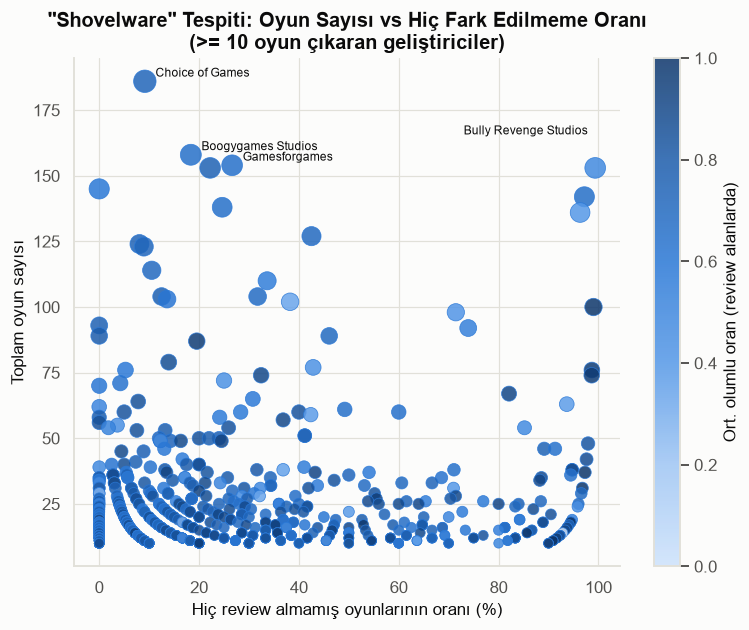

In [22]:
dev_games = dev_exp.merge(df[['app_id', 'has_enough_reviews', 'positive_ratio', 'review_label']], on='app_id')
dev_stats = dev_games.groupby('developers').agg(
    toplam_oyun=('app_id', 'size'),
    no_review_orani=('review_label', lambda s: (s == 'No Reviews').mean()),
    ort_pozitif_oran=('positive_ratio', 'mean'),
)
shovelware_candidates = dev_stats[dev_stats['toplam_oyun'] >= 10].sort_values('toplam_oyun', ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sizes = 30 + shovelware_candidates['toplam_oyun']
sc = ax.scatter(shovelware_candidates['no_review_orani'] * 100, shovelware_candidates['toplam_oyun'],
                 s=sizes, c=shovelware_candidates['ort_pozitif_oran'], cmap=SEQUENTIAL_CMAP,
                 edgecolors=CATEGORICAL_PALETTE[0], linewidths=0.5, alpha=0.85)
for name in shovelware_candidates.head(5).index:
    row = shovelware_candidates.loc[name]
    x = row['no_review_orani'] * 100
    if x > 60:
        ax.annotate(name, (x, row['toplam_oyun']), fontsize=8, ha='right',
                    xytext=(-7, 3), textcoords='offset points')
    else:
        ax.annotate(name, (x, row['toplam_oyun']), fontsize=8, ha='left',
                    xytext=(7, 3), textcoords='offset points')
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label('Ort. olumlu oran (review alanlarda)')
ax.set_title('"Shovelware" Tespiti: Oyun Sayısı vs Hiç Fark Edilmeme Oranı\n(>= 10 oyun çıkaran geliştiriciler)')
ax.set_xlabel("Hiç review almamış oyunlarının oranı (%)")
ax.set_ylabel('Toplam oyun sayısı')
save_fig(fig, '03_21_shovelware_analizi')
plt.show()

Sağ üstteki (çok oyun + çok yüksek "hiç fark edilmeme" oranı) isimler klasik
shovelware örüntüsünü gösteriyor: "EroticGamesClub" ve "Bully Revenge Studios" çıkardıkları
oyunların **%100'ünde hiç review almamış**; "Cyber Keks" ve "IR Studio" da benzer şekilde
~%97-99 oranında fark edilmemiş. Buna karşın "Choice of Games" ve "Creobit" gibi isimler de
çok sayıda oyun çıkarıyor ama oyunlarının büyük kısmı review alıyor ve ortalama olumlu oranları
yüksek (%60-78) — yani **miktar tek başına kalitesizlik göstergesi değil**; miktar + düşük
fark edilme birlikte değerlendirilmeli.

## Faz 3 Özeti

- Steam'deki oyun sayısı 2014'ten itibaren katlanarak büyüdü; fiyatlar zamanla düştü, ücretsiz
  oyun oranı arttı.
- Fiyatlandırma klasik psikolojik basamaklarda (\$0.99, \$4.99, \$9.99, ...) yoğunlaşıyor.
- Indie, veri setindeki en yaygın tür (%67); bu veri setinin genel Steam kütüphanesinden çok
  indie-yoğun bir ekosistemi temsil ettiğini gösteriyor.
- Review sayısı, sahip sayısı ve Peak CCU birbirleriyle çok yüksek korelasyonlu (hepsi
  "popülerlik"); ama olumlu oranla (kalite) korelasyonları zayıf — **popüler ≠ kaliteli**.
- Daha fazla dil ve platform desteği daha fazla erişimle (sahip sayısı) ilişkili, ama kaliteyi
  garanti etmiyor. Türkçe desteği hâlâ görece düşük (~%10) ama artış eğiliminde.
- Yayıncılı oyunlar çok daha fazla erişime sahip; "shovelware" tarzı geliştiriciler (çok sayıda
  oyun, neredeyse hiç review almayan) net şekilde tespit edilebiliyor — miktar başarı demek değil.

Bu bulgular Faz 4'teki derin analizlerin (özellikle indie-odaklı karşılaştırma ve fırsat
haritası) temelini oluşturuyor.